# NetworkX: Building a Collaboration Network from Data

In the first notebook, we created nodes and edges manually.

This notebook starts with a small table of research collaborations and uses that data to construct the graph automatically.

We will:

- create a collaboration table
- turn table rows into graph edges
- store collaboration topics as edge attributes
- visualize the network
- inspect degree
- find shortest and alternative paths

The data are fictional and intentionally small so that the network remains easy to understand.


## 1. Setup


In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt


## 2. Create Collaboration Data

Each row represents a collaboration between two researchers.

The `topic` column describes the subject of that collaboration.


In [2]:
collaborations = pd.DataFrame([
    ["Jane Lee", "John Rivera", "Mathematical Optimization"],
    ["Jane Lee", "Priya Shah", "Transportation Engineering"],
    ["Jane Lee", "Maya Chen", "Mobility Systems"],
    ["Priya Shah", "Carlos Mendes", "Urban Optimization"],
    ["Priya Shah", "Elena Rossi", "Transportation Engineering"],
    ["Priya Shah", "Maya Chen", "Mobility Systems"],
    ["Priya Shah", "Omar Hassan", "Urban Systems"],
    ["Carlos Mendes", "John Rivera", "Mathematical Optimization"],
    ["Carlos Mendes", "Elena Rossi", "Optimization"],
    ["Elena Rossi", "John Rivera", "Transportation Systems"],
    ["Maya Chen", "Fatima Ali", "Mobility Data"],
    ["Fatima Ali", "Grace Kim", "Transportation Analytics"],
    ["Grace Kim", "John Rivera", "Optimization"]
], columns=["researcher_1", "researcher_2", "topic"])

collaborations


,researcher_1,researcher_2,topic
0,Jane Lee,John Rivera,Mathematical Optimization
1,Jane Lee,Priya Shah,Transportation Engineering
2,Jane Lee,Maya Chen,Mobility Systems
3,Priya Shah,Carlos Mendes,Urban Optimization
4,Priya Shah,Elena Rossi,Transportation Engineering
5,Priya Shah,Maya Chen,Mobility Systems
6,Priya Shah,Omar Hassan,Urban Systems
7,Carlos Mendes,John Rivera,Mathematical Optimization
8,Carlos Mendes,Elena Rossi,Optimization
9,Elena Rossi,John Rivera,Transportation Systems


## 3. Build the Graph

Now each row becomes an edge.

NetworkX automatically creates the researcher nodes when the edges are added.


In [3]:
G = nx.Graph()

for _, row in collaborations.iterrows():
    G.add_edge(
        row["researcher_1"],
        row["researcher_2"],
        topic=row["topic"]
    )

print("Researchers:", G.number_of_nodes())
print("Collaborations:", G.number_of_edges())


Researchers: 9
Collaborations: 13


Inspect a few edges and their attributes.


In [4]:
list(G.edges(data=True))[:5]


[('Jane Lee', 'John Rivera', {'topic': 'Mathematical Optimization'}),
 ('Jane Lee', 'Priya Shah', {'topic': 'Transportation Engineering'}),
 ('Jane Lee', 'Maya Chen', {'topic': 'Mobility Systems'}),
 ('John Rivera', 'Carlos Mendes', {'topic': 'Mathematical Optimization'}),
 ('John Rivera', 'Elena Rossi', {'topic': 'Transportation Systems'})]

## 4. Visualize the Network


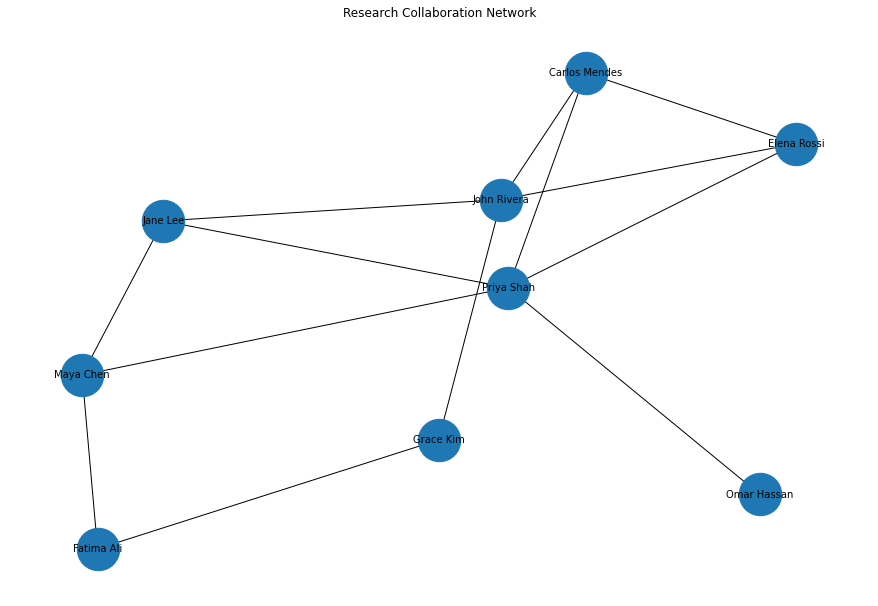

In [5]:
pos = nx.spring_layout(
    G,
    seed=42
)

plt.figure(figsize=(12, 8))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1800,
    font_size=10
)

plt.title("Research Collaboration Network")
plt.axis("off")
plt.show()


## 5. Degree

Degree counts the number of direct connections a node has.

Which researchers have the most direct collaborators?


In [6]:
degree_table = pd.DataFrame(
    G.degree(),
    columns=["researcher", "degree"]
).sort_values(
    "degree",
    ascending=False
)

degree_table


,researcher,degree
2,Priya Shah,5
1,John Rivera,4
0,Jane Lee,3
3,Maya Chen,3
4,Carlos Mendes,3
5,Elena Rossi,3
7,Fatima Ali,2
8,Grace Kim,2
6,Omar Hassan,1


## 6. Find a Shortest Path

A path is a sequence of edges connecting two nodes.

Find one shortest collaboration path between Maya Chen and John Rivera.


In [7]:
source = "Maya Chen"
target = "John Rivera"

shortest = nx.shortest_path(
    G,
    source=source,
    target=target
)

" → ".join(shortest)


'Maya Chen → Jane Lee → John Rivera'

Highlight that path in the graph.


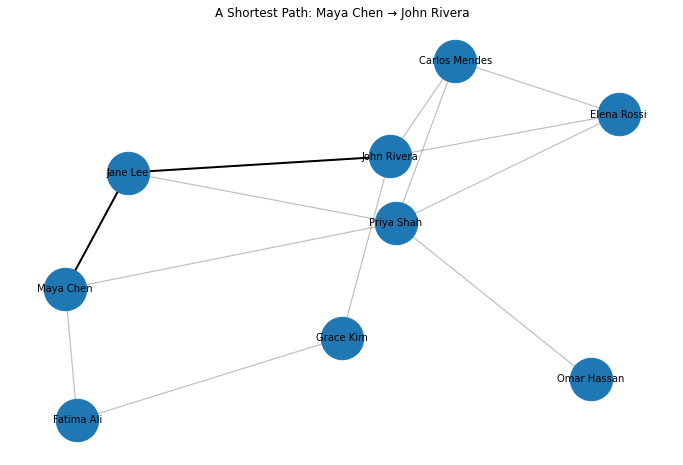

In [8]:
path_edges = list(
    zip(shortest, shortest[1:])
)

plt.figure(figsize=(12, 8))

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=1800
)

nx.draw_networkx_edges(
    G,
    pos,
    width=1.2,
    alpha=0.25
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=path_edges,
    width=2
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10
)

plt.title(
    f"A Shortest Path: {source} → {target}"
)

plt.axis("off")
plt.show()


## 7. Find Alternative Paths

A network may contain more than one route between two researchers.

Here we look for short paths between Jane Lee and John Rivera. `cutoff=4` keeps the example manageable.


In [9]:
source = "Jane Lee"
target = "John Rivera"

paths = list(
    nx.all_simple_paths(
        G,
        source=source,
        target=target,
        cutoff=4
    )
)

paths = sorted(
    paths,
    key=lambda path: (
        len(path),
        path
    )
)

for path in paths:
    print(" → ".join(path))


Jane Lee → John Rivera
Jane Lee → Priya Shah → Carlos Mendes → John Rivera
Jane Lee → Priya Shah → Elena Rossi → John Rivera
Jane Lee → Maya Chen → Fatima Ali → Grace Kim → John Rivera
Jane Lee → Maya Chen → Priya Shah → Carlos Mendes → John Rivera
Jane Lee → Maya Chen → Priya Shah → Elena Rossi → John Rivera
Jane Lee → Priya Shah → Carlos Mendes → Elena Rossi → John Rivera
Jane Lee → Priya Shah → Elena Rossi → Carlos Mendes → John Rivera


The edge attributes can help us interpret a path.

Look at the collaboration topics along one indirect route.


In [10]:
indirect_paths = [
    path
    for path in paths
    if len(path) > 2
]

path = indirect_paths[0]

for researcher_1, researcher_2 in zip(
    path,
    path[1:]
):
    topic = G[
        researcher_1
    ][researcher_2]["topic"]

    print(
        f"{researcher_1} "
        f"--[{topic}]--> "
        f"{researcher_2}"
    )


Jane Lee --[Transportation Engineering]--> Priya Shah
Priya Shah --[Urban Optimization]--> Carlos Mendes
Carlos Mendes --[Mathematical Optimization]--> John Rivera


## 8. From Example Data to Real Data

The graph model has not changed:

```text
researchers → nodes
collaborations → edges
metadata → attributes
```

What changes in a real project is where the data come from.

The same approach can be applied to publication data, patent data, organizational relationships, citations, or other sources that describe relationships between entities.

Related workshops in the Research and Patent Landscape Informatics series apply these methods to live OpenAlex and USPTO data.
